# Bayesian Surprise Map

**Family:** Spatial &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Spatial:* Use when precise locations or geographic patterns matter more than anything else.

## Design purpose

Maps how much each region's data changes what we believe, not the raw value. Several simple models predict where events should occur (equally everywhere, in proportion to population, or per-capita rates that vary by chance more in small regions). Each region is scored by the Bayesian surprise (KL divergence) its data causes across those models. Raw-count maps mostly show where people live, and per-capita maps exaggerate small regions whose rates are noisy; a surprise map discounts both effects and highlights what is genuinely unusual.

## When to use

- Mapping event counts (fraud, defaults, claims, incidents) across regions of very different size
- Choosing where to investigate first, when chance variation in small regions keeps raising false alarms
- Explaining why the per-capita leader is not necessarily the real hot spot

## Avoid when

- Regions have similar populations (a per-capita choropleth is fine)
- Readers need the actual rate (show it alongside, as here, or in a table)
- The candidate models do not represent reasonable expectations for the data

## Alternatives

- Funnel plot of rate against population with control limits
- Per-capita choropleth with uncertainty (VSUP map)
- Empirical-Bayes shrunken rates on a choropleth

## Design tips

- Show the surprise map next to the raw and per-capita maps; the contrast is the lesson
- Use a diverging palette with a gray midpoint, signed by whether the region has more or fewer events than population predicts
- The model space is a modelling choice; state which models you used
- This implementation uses normalised posteriors, as recommended by the bayesiansurpriser R package

## Example

Simulated card-fraud case counts for 50 states and DC, using approximate 2020 census populations. Four states have a genuinely different fraud rate (New York and Florida higher, Minnesota and Wisconsin lower); every state also has chance variation, which is larger for small states.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import matplotlib as mpl
from scipy.stats import norm

### Data

In [2]:
GRID = {"AK": (0, 0), "ME": (0, 11), "VT": (1, 10), "NH": (1, 11),
        "WA": (2, 1), "ID": (2, 2), "MT": (2, 3), "ND": (2, 4), "MN": (2, 5), "IL": (2, 6),
        "WI": (2, 7), "MI": (2, 8), "NY": (2, 9), "RI": (2, 10), "MA": (2, 11),
        "OR": (3, 1), "NV": (3, 2), "WY": (3, 3), "SD": (3, 4), "IA": (3, 5), "IN": (3, 6),
        "OH": (3, 7), "PA": (3, 8), "NJ": (3, 9), "CT": (3, 10),
        "CA": (4, 1), "UT": (4, 2), "CO": (4, 3), "NE": (4, 4), "MO": (4, 5), "KY": (4, 6),
        "WV": (4, 7), "VA": (4, 8), "MD": (4, 9), "DE": (4, 10),
        "AZ": (5, 2), "NM": (5, 3), "KS": (5, 4), "AR": (5, 5), "TN": (5, 6), "NC": (5, 7),
        "SC": (5, 8), "DC": (5, 9),
        "OK": (6, 4), "LA": (6, 5), "MS": (6, 6), "AL": (6, 7), "GA": (6, 8),
        "HI": (7, 0), "TX": (7, 4), "FL": (7, 9)}
# Approximate 2020 census populations (millions).
POP = {"AL": 5.0, "AK": 0.73, "AZ": 7.2, "AR": 3.0, "CA": 39.5, "CO": 5.8, "CT": 3.6, "DE": 1.0,
       "DC": 0.69, "FL": 21.5, "GA": 10.7, "HI": 1.46, "ID": 1.84, "IL": 12.8, "IN": 6.8, "IA": 3.2,
       "KS": 2.9, "KY": 4.5, "LA": 4.7, "ME": 1.36, "MD": 6.2, "MA": 7.0, "MI": 10.1, "MN": 5.7,
       "MS": 2.96, "MO": 6.2, "MT": 1.08, "NE": 1.96, "NV": 3.1, "NH": 1.38, "NJ": 9.3, "NM": 2.1,
       "NY": 20.2, "NC": 10.4, "ND": 0.78, "OH": 11.8, "OK": 4.0, "OR": 4.2, "PA": 13.0, "RI": 1.1,
       "SC": 5.1, "SD": 0.89, "TN": 6.9, "TX": 29.1, "UT": 3.3, "VT": 0.64, "VA": 8.6, "WA": 7.7,
       "WV": 1.8, "WI": 5.9, "WY": 0.58}
rng = np.random.default_rng(17)
# Simulated card-fraud cases. A few states have a genuinely higher or lower rate; on top of that,
# small states vary more by chance (fewer cardholders), which is what fools per-capita maps.
REAL_EFFECT = {"FL": 1.45, "NY": 1.35, "MN": 0.7, "WI": 0.7}
df = pd.DataFrame({"state": list(POP), "pop_m": list(POP.values())})
noise = np.exp(rng.normal(0, 0.45 / np.sqrt(df["pop_m"])))
effect = df["state"].map(REAL_EFFECT).fillna(1.0)
df["cases"] = rng.poisson(90 * df["pop_m"] * effect * noise)       # ~90 cases per million people
df["per_100k"] = df["cases"] / (df["pop_m"] * 10)
df["row"] = df["state"].map(lambda s: GRID[s][0])
df["col"] = df["state"].map(lambda s: GRID[s][1])
df.sort_values("per_100k", ascending=False).head()

,state,pop_m,cases,per_100k,row,col
27,NE,1.96,306,15.612245,4,4
32,NY,20.20,2979,14.747525,2,9
16,KS,2.90,396,13.655172,5,4
9,FL,21.50,2828,13.153488,7,9
11,HI,1.46,186,12.739726,7,0


### Plot

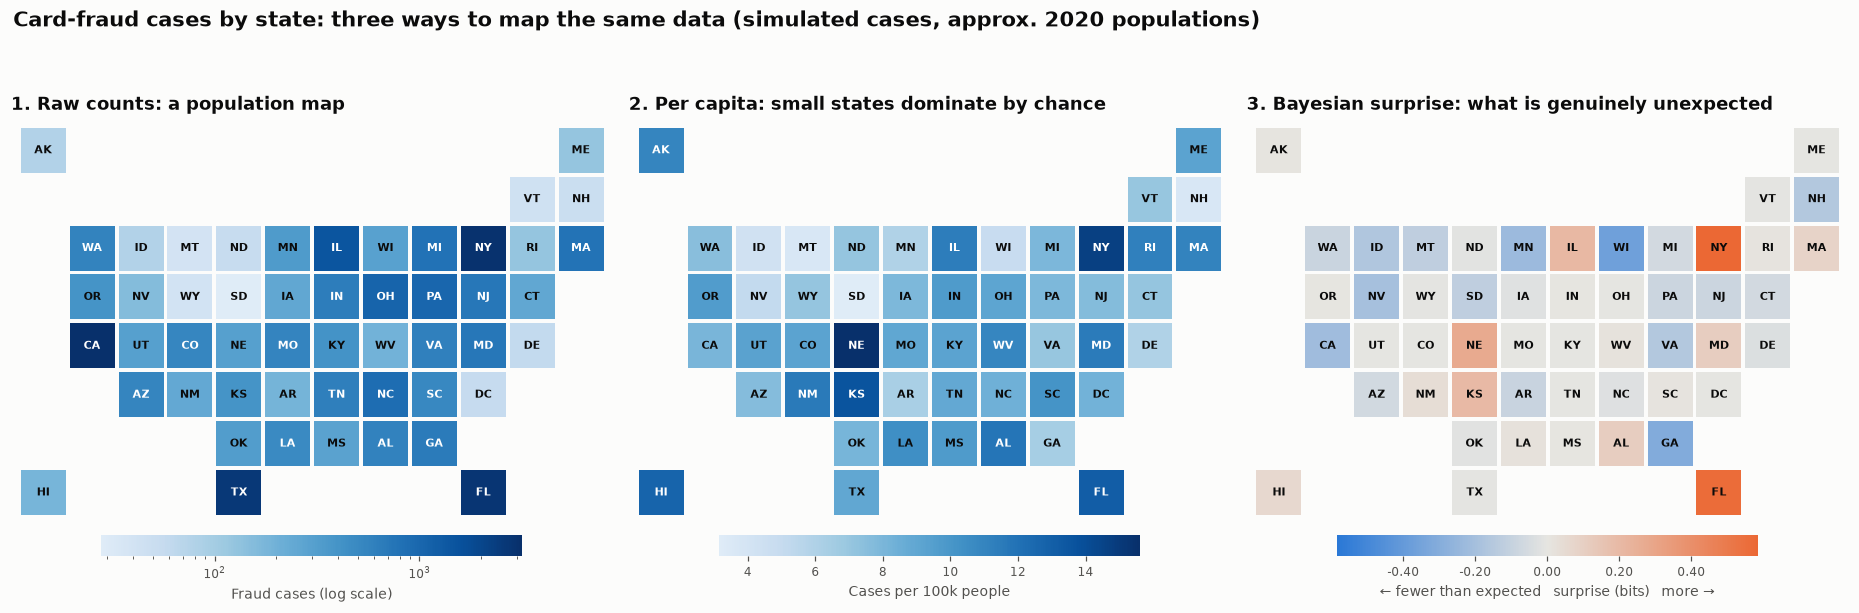

In [3]:
# Bayesian surprise (Correll & Heer 2017): each model predicts where events should be. A region is
# surprising when its data shifts belief between models; surprise = KL(posterior || prior).
obs = (df["cases"] / df["cases"].sum()).to_numpy()
pop = df["pop_m"].to_numpy()
rate = df["per_100k"].to_numpy()

expect_uniform = np.full(len(df), 1 / len(df))      # model 1: every region gets the same share
expect_base = pop / pop.sum()                       # model 2: events follow population
mean_rate = np.average(rate, weights=pop)
sigma = np.std((rate - mean_rate) * np.sqrt(pop / pop.mean()))
z = (rate - mean_rate) / (sigma / np.sqrt(pop / pop.mean()))   # model 3: de Moivre funnel

like = np.vstack([1 - np.abs(obs - expect_uniform),
                  1 - np.abs(obs - expect_base),
                  2 * (1 - norm.cdf(np.abs(z)))])   # P(data | model) for each region
prior = np.full(3, 1 / 3)
post = prior[:, None] * like
post /= post.sum(axis=0, keepdims=True)
surprise = np.sum(post * np.log2(post / prior[:, None]), axis=0)
df["surprise"] = np.sign(obs - expect_base) * surprise      # + more than population predicts

surface = "#fcfcfb"
seq = mpl.colormaps["Blues"]
diverge = mpl.colors.LinearSegmentedColormap.from_list("surprise", [PALETTE[0], "#e6e5e1", PALETTE[1]])


def ink(rgb):
    return "white" if 0.2126 * rgb[0] + 0.7152 * rgb[1] + 0.0722 * rgb[2] < 0.5 else "#0b0b0b"


def panel(ax, values, cmap, vnorm, title, cbar_label, fmt):
    for (_, r), v in zip(df.iterrows(), values):
        c = cmap(vnorm(v))
        ax.add_patch(plt.Rectangle((r.col, -r.row), 0.92, 0.92, color=c, linewidth=0))
        ax.text(r.col + 0.46, -r.row + 0.46, r.state, ha="center", va="center", fontsize=7.5,
                fontweight="bold", color=ink(c))
    ax.set_xlim(-0.2, 12.1); ax.set_ylim(-7.2, 1.1); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, fontsize=11.5)
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=vnorm, cmap=cmap), ax=ax, orientation="horizontal",
                      fraction=0.05, pad=0.02, shrink=0.7, format=fmt)
    cb.set_label(cbar_label, fontsize=9); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8)


fig, axes = plt.subplots(1, 3, figsize=(17, 5.6))
seq_trim = mpl.colors.ListedColormap(seq(np.linspace(0.12, 1, 256)))
panel(axes[0], df["cases"], seq_trim, mpl.colors.LogNorm(df["cases"].min(), df["cases"].max()),
      "1. Raw counts: a population map", "Fraud cases (log scale)", mpl.ticker.LogFormatterSciNotation())
panel(axes[1], df["per_100k"], seq_trim, mpl.colors.Normalize(df["per_100k"].min(), df["per_100k"].max()),
      "2. Per capita: small states dominate by chance", "Cases per 100k people", "%.0f")
lim = np.abs(df["surprise"]).max()
panel(axes[2], df["surprise"], diverge, mpl.colors.TwoSlopeNorm(0, -lim, lim),
      "3. Bayesian surprise: what is genuinely unexpected", "← fewer than expected   surprise (bits)   more →",
      "%.2f")
fig.suptitle("Card-fraud cases by state: three ways to map the same data (simulated cases, approx. 2020 populations)",
             x=0.01, ha="left", fontsize=13.5, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

Panel 1 mostly repeats the population map (CA, TX, FL, NY). Panel 2 puts small states such as NE and KS at the top, largely by chance. Panel 3 gives its strongest signal to NY and FL, large states with genuinely more cases, and shows WI and MN in blue; NE and KS get roughly half that signal despite topping panel 2. GA and CA also show blue: in states this large, even a modest gap from the average is hard to explain by chance.

## Reference

This method comes from the research literature:

- Correll, M. & Heer, J. (2017). Surprise! Bayesian weighting for de-biasing thematic maps. IEEE Transactions on Visualization and Computer Graphics 23(1), 651–660. <https://idl.uw.edu/papers/surprise-maps>

---
Standalone script: [`surprise_map.py`](surprise_map.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)